# Market Basket Analysis — Exploratory Data Analysis
Kushagra Dubey · Roll 2300321530109 · B.Tech CSE (AI & ML), 4th Year · ABES Engineering College, Ghaziabad

This notebook explores the cleaned retail transaction dataset (`dataset_cleaned.csv`) and produces six visualisations that motivate the association-rule mining in the main project. It is self-contained — only pandas, numpy and matplotlib are required.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

# CJK-safe font setup (per project convention; data is English)
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf',
           '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

DATA = '/home/z/my-project/download/dataset_cleaned.csv'
df = pd.read_csv(DATA, parse_dates=['timestamp'])
print(f'Rows: {len(df):,}  |  Transactions: {df.transaction_id.nunique():,}  '
      f'| Customers: {df.customer_id.nunique()}  | Products: {df.product_name.nunique()}')
df.head()

Rows: 4,849  |  Transactions: 1,274  | Customers: 601  | Products: 493


,transaction_id,customer_id,product_name,category,quantity,price,timestamp,is_anomaly,line_total,basket_size,hour,date
0,TXN000001,CUST0132,ValueMart Sparkling Water,Beverages,2,15.85,2024-01-01 08:52:00,0,31.70,3,8,2024-01-01
1,TXN000001,CUST0132,ValueMart Whole Wheat Bread,Bakery,2,1.74,2024-01-01 08:52:00,0,3.48,3,8,2024-01-01
2,TXN000001,CUST0132,CleanCare Tissue Pack,Personal Care,2,9.78,2024-01-01 08:52:00,0,19.56,3,8,2024-01-01
3,TXN000002,CUST0247,ValueMart Frozen Meals,Frozen,1,6.12,2024-01-01 09:43:00,0,6.12,3,9,2024-01-01
4,TXN000002,CUST0247,PureLife Tissue Pack,Personal Care,2,6.21,2024-01-01 09:43:00,0,12.42,3,9,2024-01-01


## 1. Cleaning summary
Rows flagged `is_anomaly = 1` and rows with non-positive quantity or price were removed; engineered columns `line_total`, `basket_size`, `hour`, `date` were added. The bar below shows the raw vs cleaned row counts and the anomaly share.

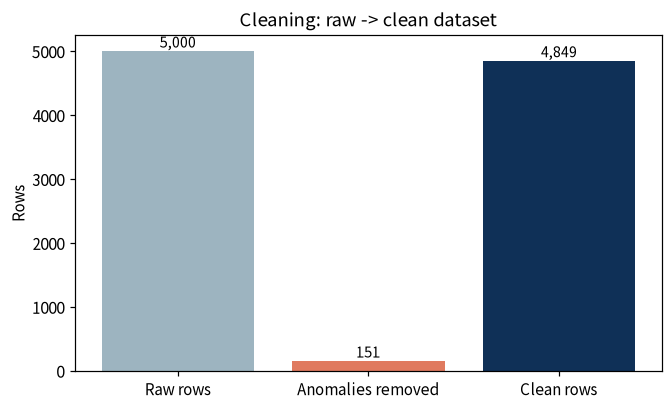

In [2]:
raw = pd.read_csv('/home/z/my-project/download/dataset.csv')
raw_n, clean_n = len(raw), len(df)
fig, ax = plt.subplots(figsize=(6,3.6), constrained_layout=True)
ax.bar(['Raw rows','Anomalies removed','Clean rows'],
       [raw_n, raw_n - clean_n, clean_n],
       color=['#9db4c0','#e07a5f','#0f3057'])
for i,v in enumerate([raw_n, raw_n - clean_n, clean_n]):
    ax.text(i, v + 60, f'{v:,}', ha='center', fontsize=9)
ax.set_ylabel('Rows'); ax.set_title('Cleaning: raw -> clean dataset')
plt.show()

## 2. Top 15 products by transaction frequency
How often each product appears across baskets — the long tail drives which items can plausibly form frequent itemsets.

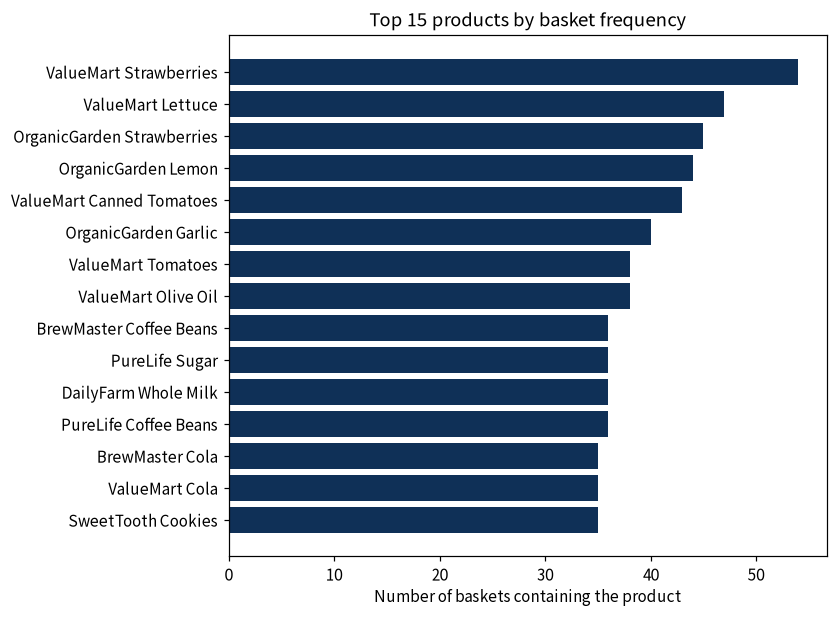

In [3]:
top = df.product_name.value_counts().head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5,5.5), constrained_layout=True)
ax.barh(top.index, top.values, color='#0f3057')
ax.set_xlabel('Number of baskets containing the product')
ax.set_title('Top 15 products by basket frequency')
plt.show()

## 3. Revenue by category
Aggregate `line_total` per category — identifies the high-value categories the cross-sell rules should prioritise.

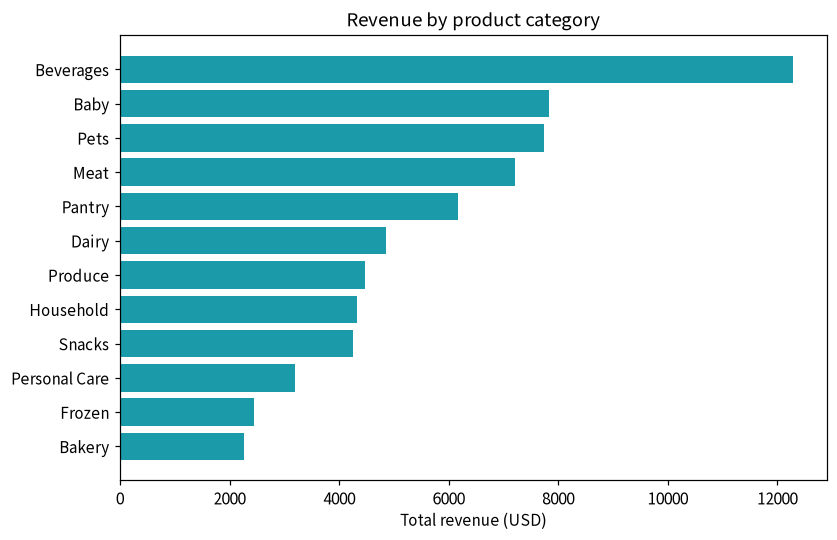

In [4]:
rev = df.groupby('category')['line_total'].sum().sort_values()
fig, ax = plt.subplots(figsize=(7.5,4.8), constrained_layout=True)
ax.barh(rev.index, rev.values, color='#1b9aaa')
ax.set_xlabel('Total revenue (USD)')
ax.set_title('Revenue by product category')
plt.show()

## 4. Basket size distribution
Number of distinct products per transaction — larger baskets give association rules more co-occurrence to work with.

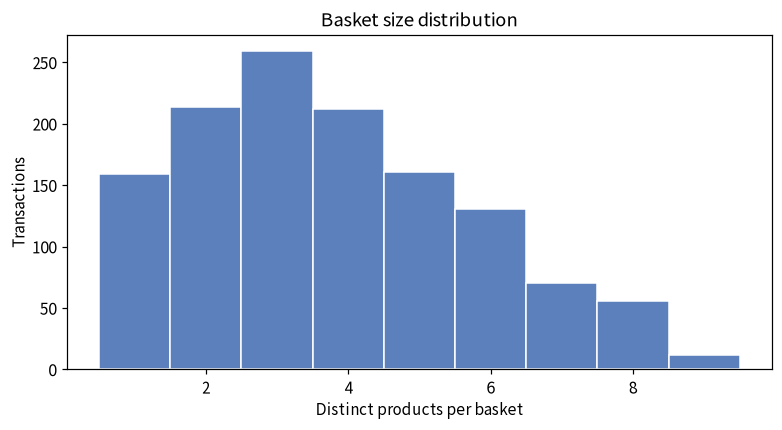

In [5]:
sizes = df.groupby('transaction_id')['product_name'].nunique()
fig, ax = plt.subplots(figsize=(7,3.8), constrained_layout=True)
ax.hist(sizes, bins=range(1, sizes.max()+2), color='#5c80bc',
        edgecolor='white', align='left')
ax.set_xlabel('Distinct products per basket'); ax.set_ylabel('Transactions')
ax.set_title('Basket size distribution')
plt.show()

## 5. Transactions by hour of day
Checkout-hour demand — operational signal for when to surface cross-sell prompts in the dashboard.

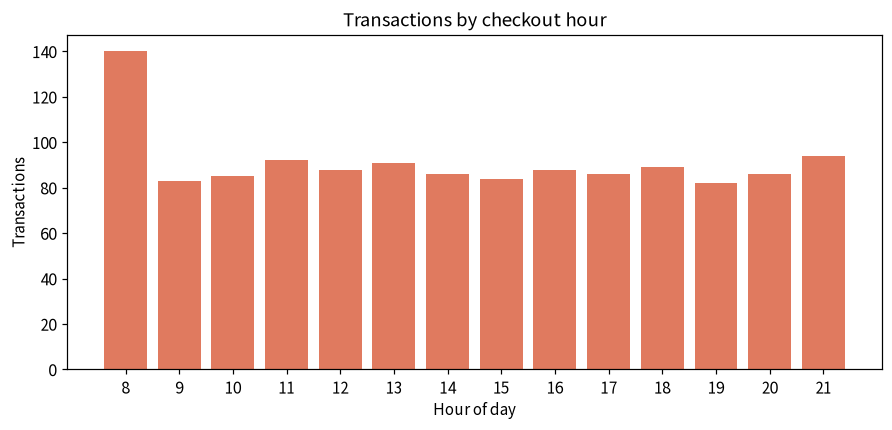

In [6]:
hourly = df.groupby('hour')['transaction_id'].nunique()
fig, ax = plt.subplots(figsize=(8,3.8), constrained_layout=True)
ax.bar(hourly.index, hourly.values, color='#e07a5f')
ax.set_xlabel('Hour of day'); ax.set_ylabel('Transactions')
ax.set_title('Transactions by checkout hour')
ax.set_xticks(hourly.index)
plt.show()

## 6. Top product co-occurrence heatmap
Pairwise co-occurrence of the 10 most frequent products — a direct preview of the associations Apriori / FP-Growth will mine as rules.

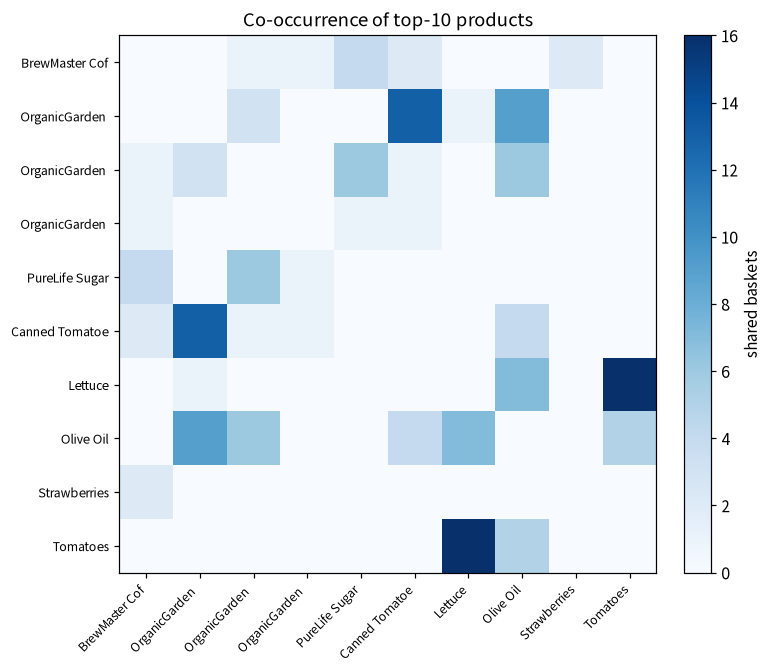

In [7]:
top10 = df.product_name.value_counts().head(10).index.tolist()
sub = df[df.product_name.isin(top10)]
mat = (sub.groupby(['transaction_id','product_name']).size()
        .unstack(fill_value=0) > 0).astype(int)
M = np.asarray(mat.values, dtype=int)
co = M.T @ M                       # writable numpy array
np.fill_diagonal(co, 0)
short = {p: p.replace('ValueMart ','').replace('FreshCo ','')[:14] for p in top10}
labels = [short[p] for p in mat.columns]
fig, ax = plt.subplots(figsize=(7.2,6), constrained_layout=True)
im = ax.imshow(co, cmap='Blues')
ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(labels, fontsize=8)
ax.set_title('Co-occurrence of top-10 products')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='shared baskets')
plt.show()

## Findings
1. About 3% of rows are anomalies and are excluded before mining.
2. Product frequency follows a long tail; a handful of SKUs appear in many baskets and anchor most rules.
3. Revenue concentrates in a few categories — the cross-sell engine should weight these.
4. Most baskets hold 3-6 products, giving association mining enough co-occurrence signal.
5. Demand peaks in late afternoon / early evening — the dashboard and API surface recommendations then.
6. The co-occurrence heatmap already reveals the bundle structure (e.g. breakfast, Italian dinner) that Apriori and FP-Growth quantify as rules with support, confidence and lift.

These six views feed directly into Section 5 (EDA) and Section 7 (Association rules) of the project report.